In [7]:
import os
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

SEED = 42

OUTPUT = Path("diabetes_portfolio_results")
OUTPUT.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")

In [8]:
df = pd.read_csv("diabetesN (3).csv")

print("Shape:", df.shape)

display(df.head())
display(df.describe().T)

print("Missing values:")
print(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Outcome counts:")
print(df["Outcome"].value_counts())

Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
Duplicate rows: 0
Outcome counts:
Outcome
0    500
1    268
Name: count, dtype: int64


In [9]:
df = pd.read_csv(r"diabetesN (3).csv")

In [10]:
# Exclude Outcome from the clustering inputs.
features = df.drop(columns="Outcome").copy()

# Retain Outcome only for later external evaluation.
y_true = df["Outcome"].astype(int).to_numpy()

zero_missing = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

print("Zeros treated as missing:")
print(features[zero_missing].eq(0).sum())

features[zero_missing] = features[zero_missing].replace(
    0, np.nan
)

imputer = SimpleImputer(strategy="median")

clean_features = pd.DataFrame(
    imputer.fit_transform(features),
    columns=features.columns,
    index=features.index
)

scaler = StandardScaler()
X_numeric = scaler.fit_transform(clean_features)

assert X_numeric.shape == (768, 8)
assert np.isfinite(X_numeric).all()
assert "Outcome" not in clean_features.columns

display(clean_features.head())

Zeros treated as missing:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6.0,148.0,72.0,35.0,125.0,33.6,0.627,50.0
1,1.0,85.0,66.0,29.0,125.0,26.6,0.351,31.0
2,8.0,183.0,64.0,29.0,125.0,23.3,0.672,32.0
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21.0
4,0.0,137.0,40.0,35.0,168.0,43.1,2.288,33.0


,k,Inertia,Silhouette
0,2,4974.937991,0.195960
1,3,4335.742198,0.195004
2,4,3912.563524,0.185496
3,5,3677.701240,0.181737
4,6,3474.502594,0.168170
5,7,3307.306732,0.122561
6,8,3145.458522,0.146312


Selected k: 2


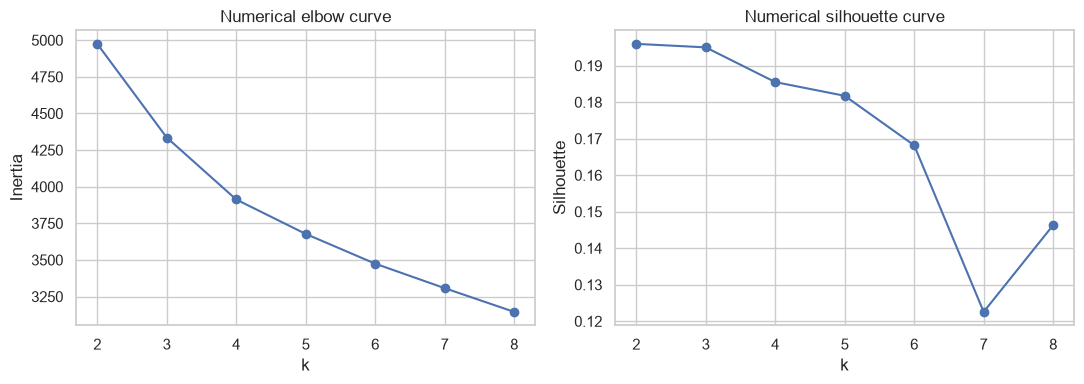

In [11]:
selection = []

for k in range(2, 9):
    km = KMeans(
        n_clusters=k,
        random_state=SEED,
        n_init=20
    )

    labels = km.fit_predict(X_numeric)

    selection.append({
        "k": k,
        "Inertia": km.inertia_,
        "Silhouette": silhouette_score(X_numeric, labels)
    })

k_table = pd.DataFrame(selection)

K = int(
    k_table.loc[k_table["Silhouette"].idxmax(), "k"]
)

display(k_table)
print("Selected k:", K)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    k_table["k"],
    k_table["Inertia"],
    marker="o"
)
axes[0].set(
    xlabel="k",
    ylabel="Inertia",
    title="Numerical elbow curve"
)

axes[1].plot(
    k_table["k"],
    k_table["Silhouette"],
    marker="o"
)
axes[1].set(
    xlabel="k",
    ylabel="Silhouette",
    title="Numerical silhouette curve"
)

fig.tight_layout()
fig.savefig(
    OUTPUT / "01_cluster_selection.png",
    dpi=180
)

plt.show()

In [12]:
def describe_row(row):
    return "; ".join(
        f"{name}: {value:.3f}"
        for name, value in row.items()
    )


documents = clean_features.apply(
    describe_row,
    axis=1
).tolist()

assert len(documents) == len(df)
assert all("Outcome" not in text for text in documents)

print("Example generated description:")
print(documents[0])

Example generated description:
Pregnancies: 6.000; Glucose: 148.000; BloodPressure: 72.000; SkinThickness: 35.000; Insulin: 125.000; BMI: 33.600; DiabetesPedigreeFunction: 0.627; Age: 50.000


In [13]:
representations = {}
models = {}
cluster_labels = {}
runtimes = {}


def fit_method(name, build_representation):
    start = time.perf_counter()

    X = build_representation()

    km = KMeans(
        n_clusters=K,
        random_state=SEED,
        n_init=20
    )

    labels = km.fit_predict(X)

    runtimes[name] = time.perf_counter() - start

    representations[name] = X
    models[name] = km
    cluster_labels[name] = labels

    print(name)
    print("Representation shape:", X.shape)
    print(
        "Cluster sizes:",
        pd.Series(labels)
        .value_counts()
        .sort_index()
        .to_dict()
    )
    print()


# Rebuild preprocessing within the timed numerical method.
def numerical_representation():
    imputed = SimpleImputer(
        strategy="median"
    ).fit_transform(features)

    return StandardScaler().fit_transform(imputed)


fit_method(
    "Numerical",
    numerical_representation
)

# Retain numeric tokens, including decimal values.
vectorizer = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+(?:\.\w+)?\b"
)

fit_method(
    "TF-IDF",
    lambda: vectorizer.fit_transform(documents)
)

Numerical
Representation shape: (768, 8)
Cluster sizes: {0: 353, 1: 415}

TF-IDF
Representation shape: (768, 1013)
Cluster sizes: {0: 270, 1: 498}



In [14]:
from sentence_transformers import SentenceTransformer

# Model loading and downloading are excluded from timing.
embedding_model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

fit_method(
    "Sentence embeddings",
    lambda: embedding_model.encode(
        documents,
        batch_size=32,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    )
)

c:\Users\User\CN6005 Portfolio\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\User\CN6005 Portfolio\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\User\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In orde

Sentence embeddings
Representation shape: (768, 384)
Cluster sizes: {0: 416, 1: 352}



,Method,k,Dimensions,Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI vs Outcome,NMI vs Outcome,Build + fit seconds
0,Numerical,2,8,0.1960,180.0073,1.9200,0.1573,0.1188,0.1085
1,TF-IDF,2,1013,0.0080,9.0152,8.7693,0.0188,0.0055,0.1451
2,Sentence embeddings,2,384,0.0734,62.5066,3.4519,0.0260,0.0311,19.9154


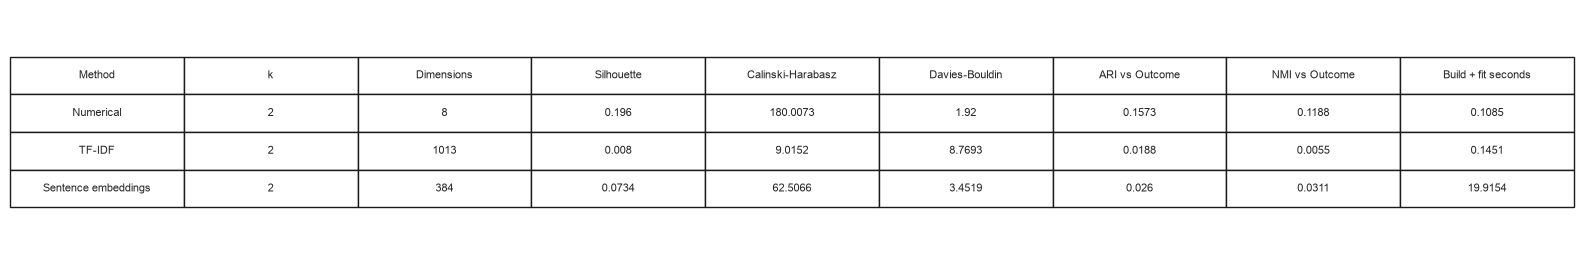

In [15]:
def evaluate_methods():
    rows = []

    for name, X in representations.items():
        labels = cluster_labels[name]

        # Convert sparse TF-IDF to dense for CH and DB metrics.
        dense = (
            X.toarray()
            if hasattr(X, "toarray")
            else np.asarray(X)
        )

        if not 1 < len(np.unique(labels)) < len(labels):
            raise ValueError(
                f"{name} did not produce a valid clustering"
            )

        rows.append({
            "Method": name,
            "k": K,
            "Dimensions": X.shape[1],
            "Silhouette": silhouette_score(X, labels),
            "Calinski-Harabasz": calinski_harabasz_score(
                dense, labels
            ),
            "Davies-Bouldin": davies_bouldin_score(
                dense, labels
            ),
            "ARI vs Outcome": adjusted_rand_score(
                y_true, labels
            ),
            "NMI vs Outcome": normalized_mutual_info_score(
                y_true, labels
            ),
            "Build + fit seconds": runtimes[name]
        })

    return pd.DataFrame(rows)


comparison = evaluate_methods()

display(comparison.round(4))

comparison.to_csv(
    OUTPUT / "comparison_table.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(16, 2.8))
ax.axis("off")

table = ax.table(
    cellText=comparison.round(4).astype(str).values,
    colLabels=comparison.columns,
    loc="center",
    cellLoc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 2)

fig.tight_layout()

fig.savefig(
    OUTPUT / "02_comparison_table.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

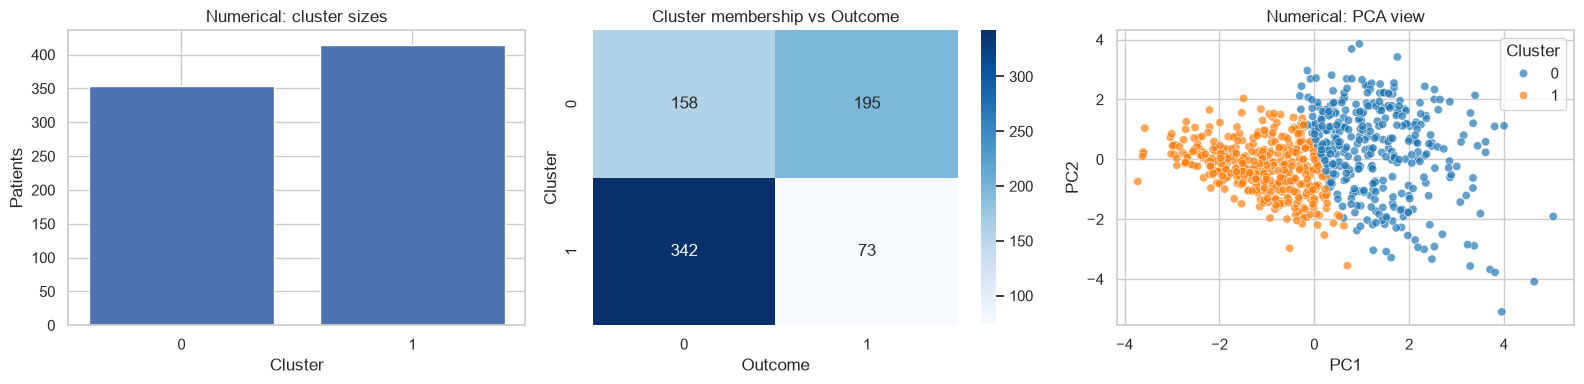

Outcome,0,1
Cluster,,
0,158,195
1,342,73


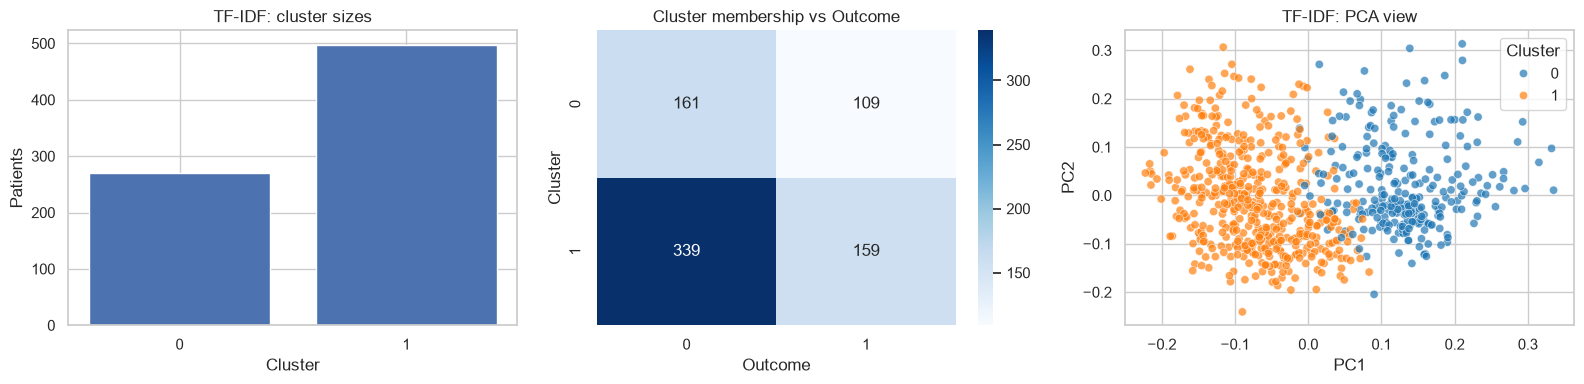

Outcome,0,1
Cluster,,
0,161,109
1,339,159


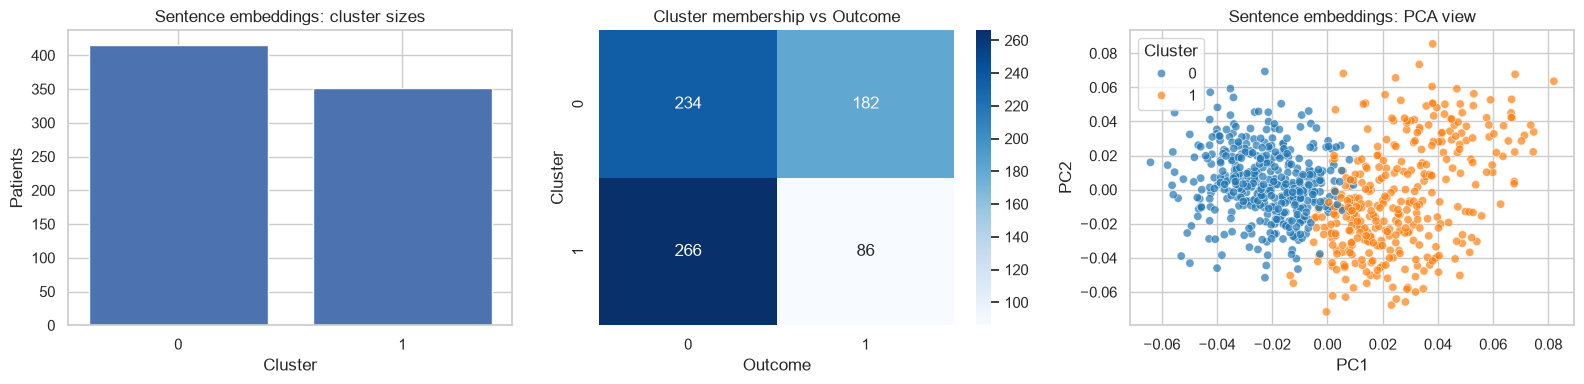

Outcome,0,1
Cluster,,
0,234,182
1,266,86


In [16]:
for index, (name, X) in enumerate(
    representations.items(),
    start=3
):
    labels = cluster_labels[name]

    dense = (
        X.toarray()
        if hasattr(X, "toarray")
        else np.asarray(X)
    )

    projection = PCA(
        n_components=2,
        random_state=SEED
    ).fit_transform(dense)

    sizes = (
        pd.Series(labels)
        .value_counts()
        .sort_index()
    )

    membership = pd.crosstab(
        pd.Series(labels, name="Cluster"),
        pd.Series(y_true, name="Outcome")
    )

    fig, axes = plt.subplots(
        1, 3,
        figsize=(16, 4)
    )

    # Cluster sizes
    axes[0].bar(
        sizes.index.astype(str),
        sizes.values
    )

    axes[0].set(
        title=f"{name}: cluster sizes",
        xlabel="Cluster",
        ylabel="Patients"
    )

    # Cluster membership versus observed Outcome
    sns.heatmap(
        membership,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[1]
    )

    axes[1].set_title(
        "Cluster membership vs Outcome"
    )

    # Two-dimensional PCA projection
    sns.scatterplot(
        x=projection[:, 0],
        y=projection[:, 1],
        hue=labels.astype(str),
        palette="tab10",
        alpha=0.7,
        ax=axes[2]
    )

    axes[2].set(
        title=f"{name}: PCA view",
        xlabel="PC1",
        ylabel="PC2"
    )

    axes[2].legend(title="Cluster")

    fig.tight_layout()

    fig.savefig(
        OUTPUT / f"{index:02d}_clusters.png",
        dpi=180
    )

    plt.show()
    display(membership)

In [17]:
assignments = df.copy()

for name, labels in cluster_labels.items():
    assignments[name + " cluster"] = labels

    profile = (
        clean_features
        .assign(Cluster=labels)
        .groupby("Cluster")
        .mean()
    )

    profile["Patients"] = (
        pd.Series(labels)
        .value_counts()
        .reindex(profile.index)
    )

    profile["Outcome 1 proportion"] = (
        pd.Series(y_true)
        .groupby(labels)
        .mean()
    )

    print("\n", name, "cluster profiles")
    display(profile.round(3))

    profile.to_csv(
        OUTPUT / (
            name.replace(" ", "_") + "_profiles.csv"
        )
    )

    for cluster in sorted(np.unique(labels)):
        patient_index = np.flatnonzero(
            labels == cluster
        )[0]

        print(
            f"Cluster {cluster}, "
            f"example row {patient_index}: "
            f"{documents[patient_index]}"
        )

assignments.to_csv(
    OUTPUT / "patient_cluster_assignments.csv",
    index=False
)

k_table.to_csv(
    OUTPUT / "k_selection.csv",
    index=False
)

print("Saved results to:", OUTPUT.resolve())


 Numerical cluster profiles


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Patients,Outcome 1 proportion
Cluster,,,,,,,,,,
0,5.759,137.841,78.904,32.728,168.697,35.281,0.505,41.025,353,0.552
1,2.217,107.889,66.843,26.029,116.834,30.052,0.444,26.619,415,0.176


Cluster 0, example row 0: Pregnancies: 6.000; Glucose: 148.000; BloodPressure: 72.000; SkinThickness: 35.000; Insulin: 125.000; BMI: 33.600; DiabetesPedigreeFunction: 0.627; Age: 50.000
Cluster 1, example row 1: Pregnancies: 1.000; Glucose: 85.000; BloodPressure: 66.000; SkinThickness: 29.000; Insulin: 125.000; BMI: 26.600; DiabetesPedigreeFunction: 0.351; Age: 31.000

 TF-IDF cluster profiles


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Patients,Outcome 1 proportion
Cluster,,,,,,,,,,
0,4.622,123.396,74.596,29.348,129.959,31.591,0.406,36.715,270,0.404
1,3.424,120.713,71.189,28.978,146.480,32.924,0.507,31.357,498,0.319


Cluster 0, example row 0: Pregnancies: 6.000; Glucose: 148.000; BloodPressure: 72.000; SkinThickness: 35.000; Insulin: 125.000; BMI: 33.600; DiabetesPedigreeFunction: 0.627; Age: 50.000
Cluster 1, example row 3: Pregnancies: 1.000; Glucose: 89.000; BloodPressure: 66.000; SkinThickness: 23.000; Insulin: 94.000; BMI: 28.100; DiabetesPedigreeFunction: 0.167; Age: 21.000

 Sentence embeddings cluster profiles


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Patients,Outcome 1 proportion
Cluster,,,,,,,,,,
0,6.147,126.010,74.752,29.846,144.731,32.795,0.475,38.675,416,0.438
1,1.125,116.511,69.591,28.236,135.875,32.054,0.468,26.818,352,0.244


Cluster 0, example row 0: Pregnancies: 6.000; Glucose: 148.000; BloodPressure: 72.000; SkinThickness: 35.000; Insulin: 125.000; BMI: 33.600; DiabetesPedigreeFunction: 0.627; Age: 50.000
Cluster 1, example row 1: Pregnancies: 1.000; Glucose: 85.000; BloodPressure: 66.000; SkinThickness: 29.000; Insulin: 125.000; BMI: 26.600; DiabetesPedigreeFunction: 0.351; Age: 31.000
Saved results to: C:\Users\User\CN6005 Portfolio\Week 5\diabetes_portfolio_results
